In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)


In [ ]:
path = "stock_data.csv"
df = pd.read_csv(path)
print("Shape:", df.shape)

Shape: (1444, 7)


In [ ]:
# Parse date + sort
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df = df.dropna(subset=["Date"]).sort_values("Date").reset_index(drop=True)

# Ensure numeric columns are numeric
num_cols = ["Open", "High", "Low", "Close", "Volume","Adj Close"]
for c in num_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")

df = df.dropna(subset=num_cols).reset_index(drop=True)

print("After cleaning:", df.shape)
print(df[["Date"] + num_cols].head())


After cleaning: (566, 7)
        Date       Open       High        Low      Close    Volume  Adj Close
0 2019-01-07  46.980000  47.040001  44.060001  44.270000  17660500  44.270000
1 2019-01-08  42.139999  42.535999  41.000000  41.310001   7349700  41.310001
2 2019-01-10  30.370001  30.510000  28.650000  29.150000  13380200  29.150000
3 2019-01-11  31.450001  31.700001  30.740999  31.370001  10434300  31.370001
4 2019-02-07  44.549999  44.680000  43.750000  44.000000  11881300  44.000000


In [ ]:
# Daily log returns (more stable than simple returns)
df["log_return"] = np.log(df["Adj Close"]).diff()

# Feature engineering: market-derived indicators
df["hl_range"] = (df["High"] - df["Low"]) / df["Open"]          # intraday range scaled
df["co_return"] = (df["Close"] - df["Open"]) / df["Open"]       # open-to-close return
df["vol_chg"] = df["Volume"].pct_change()                       # volume change

# Rolling stats (feature windows)
for w in [5, 10, 20]:
    df[f"ret_mean_{w}"] = df["log_return"].rolling(w).mean()
    df[f"ret_std_{w}"]  = df["log_return"].rolling(w).std()
    df[f"vol_mean_{w}"] = df["Volume"].rolling(w).mean()

# Volatility target (realised volatility)
VOL_WINDOW = 10
df["realised_vol"] = df["log_return"].rolling(VOL_WINDOW).std()

# Predict NEXT day volatility (supervised learning target)
df["target_vol_next"] = df["realised_vol"].shift(-1)

# Drop rows with NaNs created by rolling/shift
df_model = df.dropna().reset_index(drop=True)

print("Model dataset shape:", df_model.shape)
df_model[["Date", "log_return", "realised_vol", "target_vol_next"]].tail()


Model dataset shape: (545, 22)


,Date,log_return,realised_vol,target_vol_next
540,2025-04-02,0.035906,0.059345,0.063277
541,2025-05-02,-0.078562,0.063277,0.064578
542,2025-06-01,0.027986,0.064578,0.063337
543,2025-07-01,-0.002416,0.063337,0.063381
544,2025-08-01,-0.018923,0.063381,0.061294


# EDA (Market dervied Indicators)

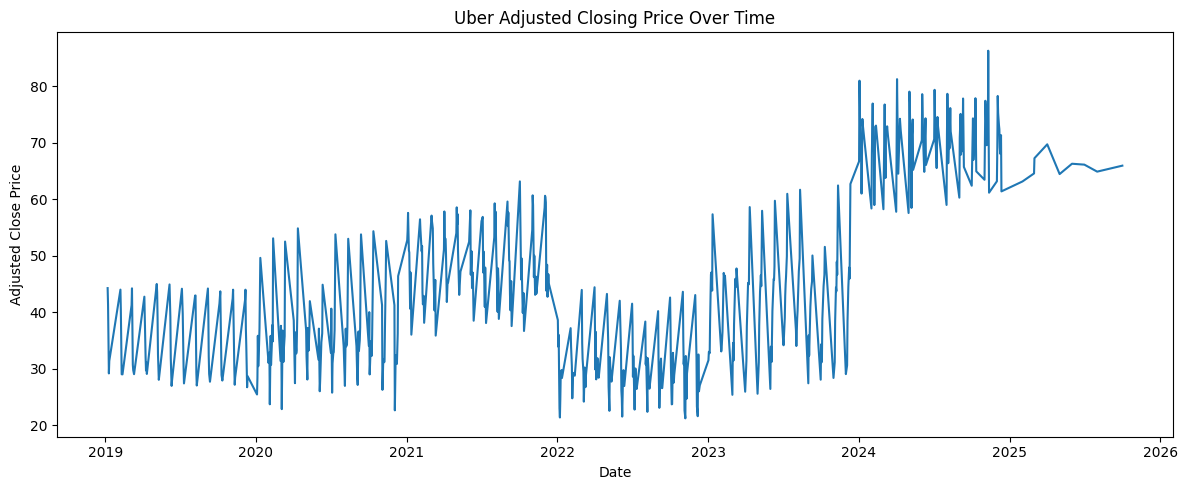

In [ ]:
plt.figure(figsize=(12,5))
plt.plot(df["Date"], df["Adj Close"])
plt.title("Uber Adjusted Closing Price Over Time")
plt.xlabel("Date")
plt.ylabel("Adjusted Close Price")
plt.tight_layout()
plt.show()


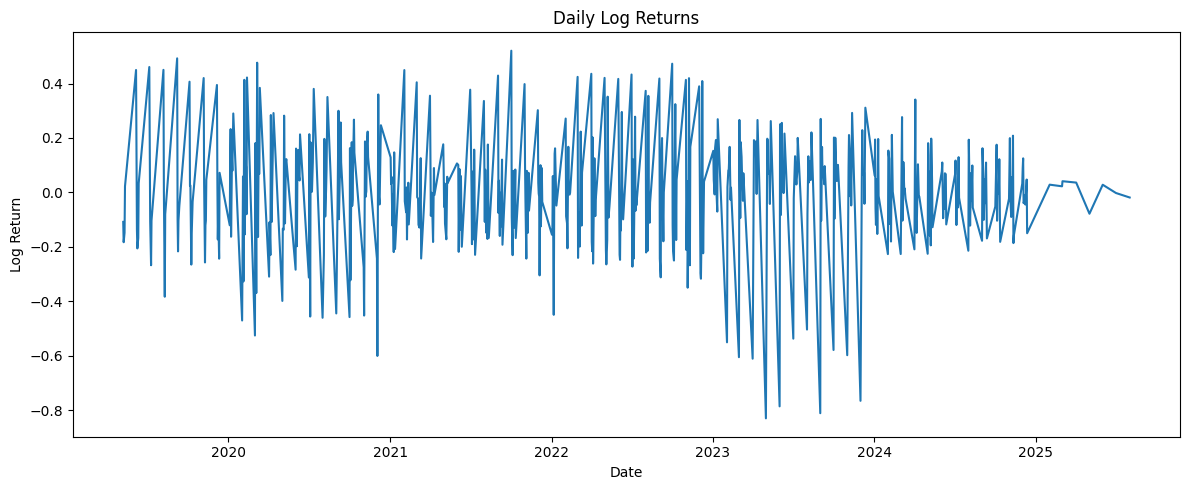

In [ ]:
plt.figure(figsize=(12,5))
plt.plot(df_model["Date"], df_model["log_return"])
plt.title("Daily Log Returns")
plt.xlabel("Date")
plt.ylabel("Log Return")
plt.tight_layout()
plt.show()

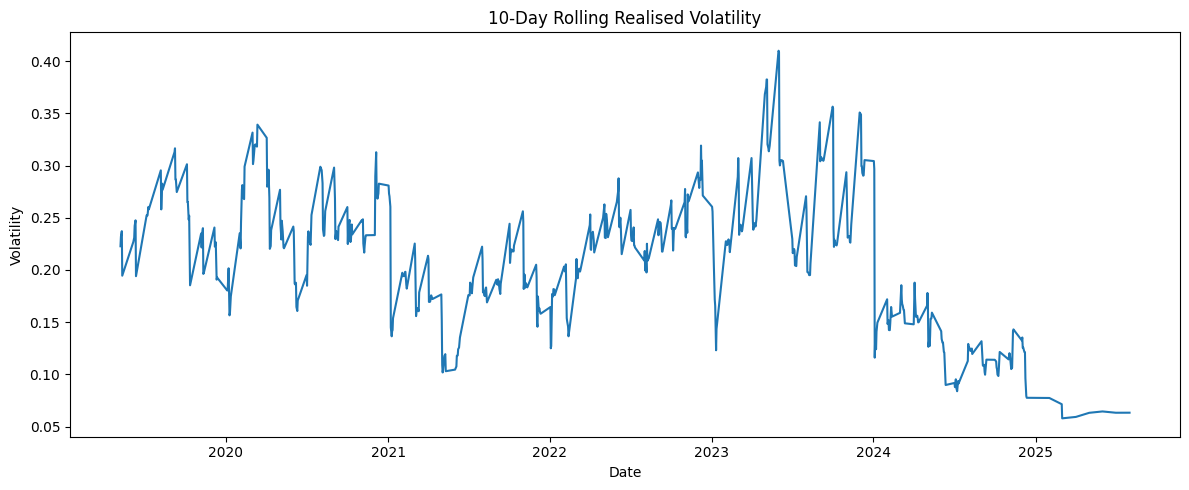

In [ ]:
plt.figure(figsize=(12,5))
plt.plot(df_model["Date"], df_model["realised_vol"])
plt.title("10-Day Rolling Realised Volatility")
plt.xlabel("Date")
plt.ylabel("Volatility")
plt.tight_layout()
plt.show()


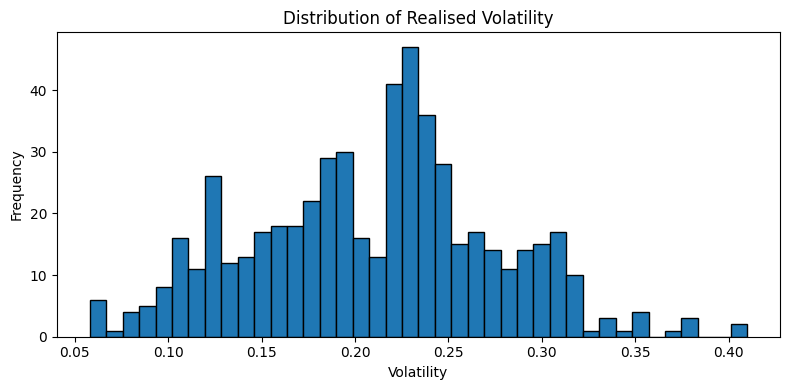

In [ ]:
plt.figure(figsize=(8,4))
plt.hist(df_model["realised_vol"], bins=40,edgecolor = 'black')
plt.title("Distribution of Realised Volatility")
plt.xlabel("Volatility")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


In [ ]:
features = [
    "hl_range", "co_return", "vol_chg",
    "ret_mean_5", "ret_std_5", "vol_mean_5",
    "ret_mean_10", "ret_std_10", "vol_mean_10",
    "ret_mean_20", "ret_std_20", "vol_mean_20"
]

X = df_model[features]
y = df_model["target_vol_next"]

# Time-based split (80/20)
split_idx = int(len(df_model) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Train dates:", df_model.loc[:split_idx, "Date"].min(), "to", df_model.loc[:split_idx, "Date"].max())
print("Test dates:", df_model.loc[split_idx:, "Date"].min(), "to", df_model.loc[split_idx:, "Date"].max())


Train: (436, 12) Test: (109, 12)
Train dates: 2019-05-08 00:00:00 to 2024-01-03 00:00:00
Test dates: 2024-01-03 00:00:00 to 2025-08-01 00:00:00


In [ ]:
def evaluate(y_true, y_pred, name="Model"):
    y_true = np.array(y_true).ravel()
    y_pred = np.array(y_pred).ravel()

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    print(f"\n{name}")
    print(f"MAE : {mae:.6f}")
    print(f"RMSE: {rmse:.6f}")
    print(f"R²  : {r2:.4f}")

    return {"model": name, "MAE": mae, "RMSE": rmse, "R2": r2}


In [ ]:
# Ridge Regression (with scaling)
ridge_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=1.0))
])

ridge_model.fit(X_train, y_train)

ridge_pred = ridge_model.predict(X_test)

ridge_results = evaluate(y_test, ridge_pred, "Ridge (Scaled)")



Ridge (Scaled)
MAE : 0.014979
RMSE: 0.023518
R²  : 0.3903


In [ ]:
# Random Forest
rf_model = RandomForestRegressor(
    n_estimators=500,
    random_state=42,
    n_jobs=-1,
    max_depth=None,
    min_samples_leaf=2
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

rf_results = evaluate(y_test, rf_pred, "Random Forest")



Random Forest
MAE : 0.017386
RMSE: 0.026462
R²  : 0.2280


In [ ]:
# Gradient Boosting
gbr_model = GradientBoostingRegressor(
    random_state=42
)

gbr_model.fit(X_train, y_train)

gbr_pred = gbr_model.predict(X_test)

gbr_results = evaluate(y_test, gbr_pred, "Gradient Boosting")



Gradient Boosting
MAE : 0.021759
RMSE: 0.031736
R²  : -0.1103


In [ ]:
# comparing all Models
results_df = pd.DataFrame([
    ridge_results,
    rf_results,
    gbr_results
]).sort_values("RMSE")

results_df


,model,MAE,RMSE,R2
0,Ridge (Scaled),0.014979,0.023518,0.390284
1,Random Forest,0.017386,0.026462,0.228045
2,Gradient Boosting,0.021759,0.031736,-0.110282


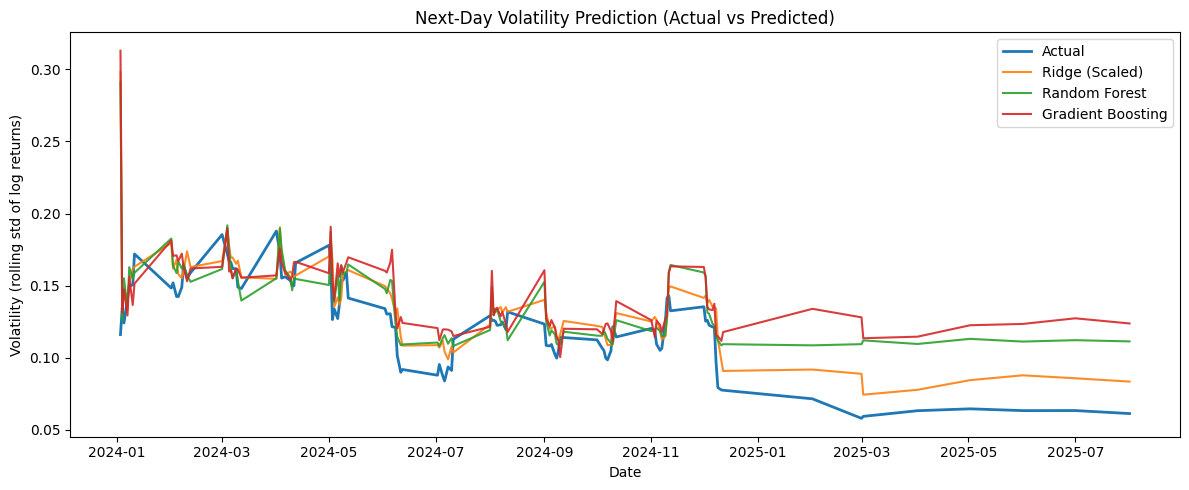

In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(df_model["Date"].iloc[split_idx:], y_test.values, label="Actual", linewidth=2)

# Re-create the preds dictionary with available predictions from 'Market Only' models
preds = {
    "Ridge (Scaled)": ridge_pred,
    "Random Forest": rf_pred,
    "Gradient Boosting": gbr_pred
}

for name, y_pred in preds.items():
    plt.plot(df_model["Date"].iloc[split_idx:], y_pred, label=name, alpha=0.9)

plt.title("Next-Day Volatility Prediction (Actual vs Predicted)")
plt.xlabel("Date")
plt.ylabel("Volatility (rolling std of log returns)")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
from pandas_datareader import data as pdr
import datetime as dt

start = df_model["Date"].min()
end   = df_model["Date"].max()

macro_series = {
    "fed_funds": "FEDFUNDS",
    "unrate": "UNRATE",
    "dgs10": "DGS10",
    "cpi": "CPIAUCSL"
}

macro_df = pd.DataFrame()

for name, code in macro_series.items():
    macro_df[name] = pdr.DataReader(code, "fred", start, end)

macro_df = macro_df.reset_index().rename(columns={"DATE": "Date"})
macro_df.head()


,Date,fed_funds,unrate,dgs10,cpi
0,2019-06-01,2.38,3.6,NaN,255.213
1,2019-07-01,2.40,3.7,2.03,255.802
2,2019-08-01,2.13,3.6,1.90,256.036
3,2019-09-01,2.04,3.5,NaN,256.430
4,2019-10-01,1.83,3.6,1.65,257.155


In [ ]:
# Merge with stock dataframe
df_macro = pd.merge(
    df_model,
    macro_df,
    on="Date",
    how="left"
)

# Forward-fill macro indicators
macro_cols = list(macro_series.keys())
df_macro[macro_cols] = df_macro[macro_cols].ffill()

# EDA(Market + Marcoeconomic Indicators)

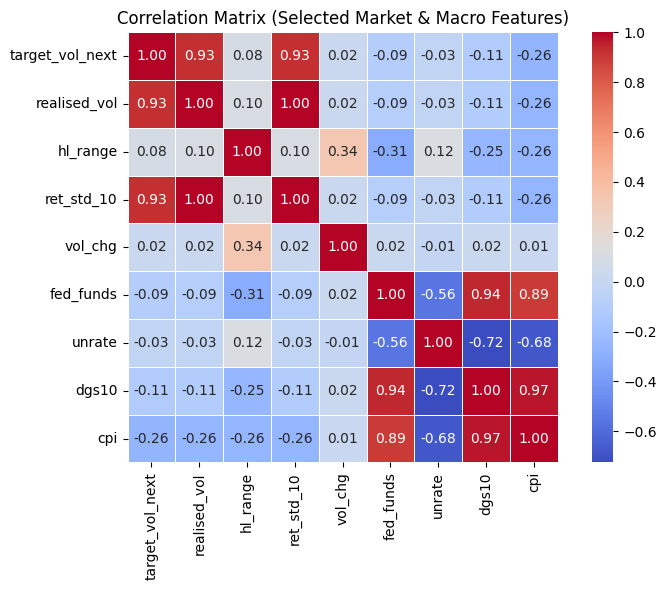

In [ ]:
selected_cols = ["target_vol_next","realised_vol","hl_range","ret_std_10","vol_chg","fed_funds","unrate","dgs10","cpi"]
corr_small = df_macro[selected_cols].corr()
plt.figure(figsize=(8,6))
sns.heatmap(
    corr_small,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    square=True
)

plt.title("Correlation Matrix (Selected Market & Macro Features)")
plt.tight_layout()
plt.show()



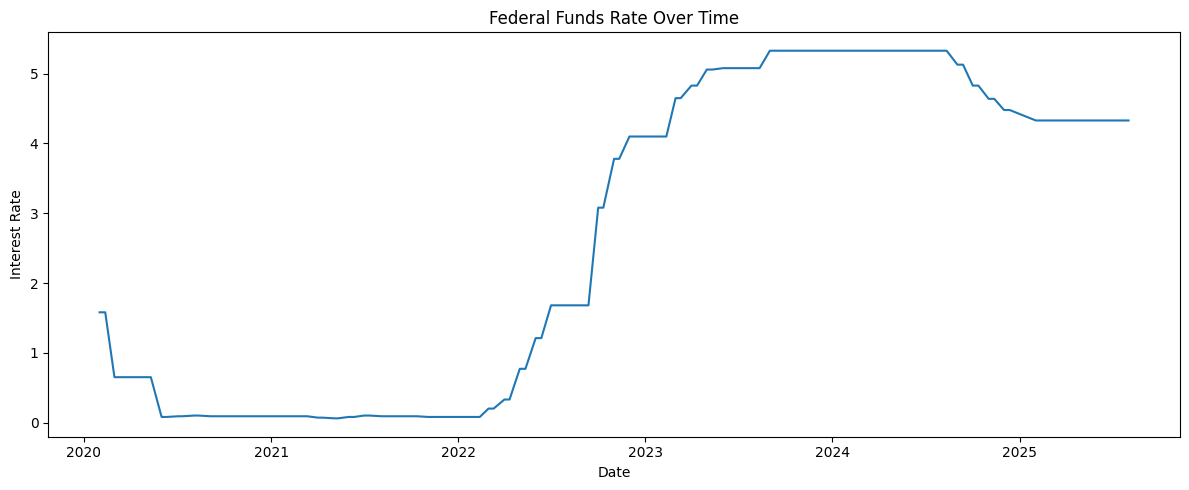

In [ ]:
#Federal Funds Rate Over Time
plt.figure(figsize=(12,5))
plt.plot(df_macro["Date"], df_macro["fed_funds"])
plt.title("Federal Funds Rate Over Time")
plt.xlabel("Date")
plt.ylabel("Interest Rate")
plt.tight_layout()
plt.show()


In [ ]:
# Percentage changes (economic momentum)
df_macro["fed_funds_chg"] = df_macro["fed_funds"].pct_change()
df_macro["unrate_chg"]    = df_macro["unrate"].diff()
df_macro["dgs10_chg"]     = df_macro["dgs10"].pct_change()
df_macro["cpi_inflation"] = df_macro["cpi"].pct_change()

# Drop NaNs after feature creation
df_macro = df_macro.dropna().reset_index(drop=True)

In [ ]:
market_features = [
    "hl_range", "co_return", "vol_chg",
    "ret_mean_5", "ret_std_5",
    "ret_mean_10", "ret_std_10",
    "ret_mean_20", "ret_std_20"
]

macro_features = [
    "fed_funds", "unrate", "dgs10", "cpi",
    "fed_funds_chg", "unrate_chg", "dgs10_chg", "cpi_inflation"
]

X = df_macro[market_features + macro_features]
y = df_macro["target_vol_next"]

# Time-based split
split_idx = int(len(df_macro) * 0.8)

X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print("Train:", X_train.shape, "Test:", X_test.shape)


Train: (371, 17) Test: (93, 17)


In [ ]:
def evaluate(y_true, y_pred, name="Model"):
    y_true = np.array(y_true).ravel()
    y_pred = np.array(y_pred).ravel()

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    print(f"\n{name}")
    print(f"MAE : {mae:.6f}")
    print(f"RMSE: {rmse:.6f}")
    print(f"R²  : {r2:.4f}")

    return {"model": name, "MAE": mae, "RMSE": rmse, "R2": r2}


In [ ]:
# Random Forest (Market + Macro)
rf_macro = RandomForestRegressor(
    n_estimators=600,
    random_state=42,
    n_jobs=-1,
    min_samples_leaf=2
)

rf_macro.fit(X_train, y_train)

rf_macro_pred = rf_macro.predict(X_test)

rf_macro_results = evaluate(
    y_test,
    rf_macro_pred,
    "Random Forest (Market + Macro)"
)



Random Forest (Market + Macro)
MAE : 0.019069
RMSE: 0.023676
R²  : 0.3699


In [ ]:
# Gradient Boosting (Market + Macro)
gbr_macro = GradientBoostingRegressor(
    random_state=42
)

gbr_macro.fit(X_train, y_train)

gbr_macro_pred = gbr_macro.predict(X_test)

gbr_macro_results = evaluate(
    y_test,
    gbr_macro_pred,
    "Gradient Boosting (Market + Macro)"
)



Gradient Boosting (Market + Macro)
MAE : 0.028253
RMSE: 0.034141
R²  : -0.3103


In [ ]:
results_macro_df = pd.DataFrame([
    ridge_macro_results,
    rf_macro_results,
    gbr_macro_results
]).sort_values("RMSE")

results_macro_df


,model,MAE,RMSE,R2
0,Ridge (Market + Macro),0.020395,0.022428,0.434567
1,Random Forest (Market + Macro),0.019069,0.023676,0.369853
2,Gradient Boosting (Market + Macro),0.028253,0.034141,-0.310288


# Comparing Both Market Dervied and Macro economic indicators

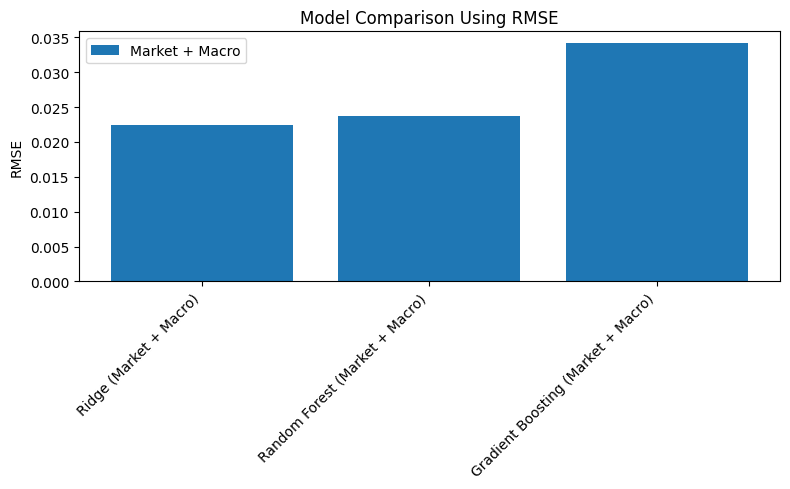

In [ ]:
plt.figure(figsize=(8, 5))

for set_name in results_all["Set"].unique():
    subset = results_all[results_all["Set"] == set_name]
    plt.bar(
        subset["model"] ,
        subset["RMSE"],
        label=set_name
    )

plt.xticks(rotation=45, ha="right")
plt.ylabel("RMSE")
plt.title("Model Comparison Using RMSE")
plt.legend()
plt.tight_layout()
plt.show()
